# Validation croisee, optimisation et modele retenu

On compare les trois familles avec une validation imbriquee : 5 plis externes pour mesurer,
3 plis internes pour regler. Le preprocessing est dans le pipeline et se reapprend dans chaque pli.
Le choix vient du F1 macro de validation. Un seul fichier modele est sauvegarde a la fin.
Projet pedagogique, sans usage clinique.


## 1. Donnees

Reprendre le meme split de 1600 lignes train et 400 test.
Encoder la cible sur le train seulement. La liste categories_[0] sera sauvegardee avec le pipeline
pour reconvertir les codes des predictions en libelles.
Le test a deja ete consulte dans les essais precedents : il ne doit guider aucun nouveau reglage.


In [16]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.optimize import optimize_model, cross_validate_model
from src.evaluate import evaluate_model

folder = PROJECT_ROOT / "metrique"
folder.mkdir(exist_ok=True)
models_folder = PROJECT_ROOT / "models"
models_folder.mkdir(exist_ok=True)

# la meme chose split ....
df = pd.read_csv(PROJECT_ROOT / "data/raw/student_mental_health.csv")
df = df.drop_duplicates().dropna(subset=["Mental_Health_Risk"])
X = df.drop(columns=["Student_ID", "Mental_Health_Risk"])
y = df["Mental_Health_Risk"]
X_train, X_test, y_train_text, y_test_text = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
encoder = OrdinalEncoder(categories=[["Low", "Medium", "High"]])
y_train = encoder.fit_transform(y_train_text.to_frame()).astype(int).ravel()
class_names = encoder.categories_[0]


## 2. Parametres a essayer

Les cles model__... indiquent les parametres de l'etape model du Pipeline.
C regle la regularisation de la regression logistique ; max_depth la profondeur des arbres ;
n_estimators leur nombre. La grille reste petite : elle ne garantit pas un optimum global.
Le critere de recherche est le F1 macro, pas la performance sur le train.


In [17]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, 
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        random_state=42, 
        n_jobs=2
    ),
    "XGBoost": XGBClassifier(
        learning_rate=0.05, 
        subsample=0.8, 
        colsample_bytree=0.8,
        objective="multi:softprob", 
        eval_metric="mlogloss",
        tree_method="hist", 
        random_state=42, 
        n_jobs=2,
    ),
}
parameters = {
    "Logistic Regression": {
        "model__C": [0.1, 1, 10]
        },
    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [8, None],
        "model__min_samples_leaf": [2],
    },
    "XGBoost": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [2, 3],
    },
}
validation = {}


## 3. Validation croisee imbriquee

Dans chaque pli externe, 1280 lignes servent a l'optimisation interne et 320 restent a l'ecart.
GridSearchCV cherche sur les 3 plis internes puis reentraine sur les 1280 lignes.
Ce pipeline predit ensuite les 320 lignes externes, sans les avoir vues.
Apres 5 plis, chaque ligne du train possede une prediction hors pli.
Cette separation evite d'evaluer les reglages sur les memes lignes qui les ont choisis.


In [18]:
name = "Logistic Regression"
print(name, flush=True)
validation[name] = cross_validate_model(
    models[name], parameters[name], X_train, y_train, class_names
)


Logistic Regression
Pli 1 termine
Pli 2 termine
Pli 3 termine
Pli 4 termine
Pli 5 termine


In [19]:
name = "Random Forest"
print(name, flush=True)
validation[name] = cross_validate_model(
    models[name], parameters[name], X_train, y_train, class_names
)


Random Forest
Pli 1 termine
Pli 2 termine
Pli 3 termine
Pli 4 termine
Pli 5 termine


In [20]:
name = "XGBoost"
print(name, flush=True)
validation[name] = cross_validate_model(
    models[name], parameters[name], X_train, y_train, class_names
)


XGBoost
Pli 1 termine
Pli 2 termine
Pli 3 termine
Pli 4 termine
Pli 5 termine


## 4. Choisir sur la validation

On calcule les metriques a partir de toutes les predictions hors pli.
idxmax retrouve le modele au meilleur F1 macro. Le choix est fixe avant les scores test.
cv_fold_metrics.csv garde les scores des 5 plis de chaque modele pour observer leur variation.
La variation entre plis et les comparaisons deja repetees limitent la certitude du classement.


In [ ]:
validation_rows = []
fold_tables = []

for name, result in validation.items():
    validation_rows.append({"Modele": name, **result["evaluation"]["metrics"]})
    fold_tables.append(result["folds"].assign(Modele=name))

validation_scores = pd.DataFrame(validation_rows).set_index("Modele")
selected_name = validation_scores["F1 macro"].idxmax()
fold_scores = pd.concat(fold_tables, ignore_index=True)
fold_scores.to_csv(folder / "cv_fold_metrics.csv", index=False)
display(validation_scores.round(4))
print("Modele retenu sur validation :", selected_name)


,Accuracy,Precision macro,Recall macro,F1 macro,ROC AUC macro OvR
Modele,,,,,
Logistic Regression,0.7519,0.7499,0.7512,0.7505,0.9023
Random Forest,0.6775,0.6703,0.6765,0.6725,0.8559
XGBoost,0.6944,0.6893,0.6934,0.6910,0.8639


Modele retenu sur validation : Logistic Regression


## 5. Entrainer les pipelines finaux et sauvegarder seulement le meilleur

Chaque famille est reoptimisee sur les 1600 lignes train pour permettre la comparaison finale.
Les trois pipelines restent en memoire. Seul celui retenu par la validation est enregistre.
Le fichier contient le pipeline complet, l'OrdinalEncoder, les noms des classes, les parametres
et le nombre de lignes d'apprentissage. Aucun perdant n'est sauvegarde.


In [7]:
optimized_models = {}
best_parameters = {}
for name, model in models.items():
    search = optimize_model(model, parameters[name], X_train, y_train)
    optimized_models[name] = search.best_estimator_
    best_parameters[name] = search.best_params_
    print(name, search.best_params_)

# Choix effectue auparavant sur la validation, jamais sur le test.
best_bundle = {
    "model_name": selected_name,
    "pipeline": optimized_models[selected_name],
    "target_encoder": encoder,
    "class_names": class_names,
    "training_rows": len(X_train),
    "best_parameters": best_parameters[selected_name],
    "selection_metric": "F1 macro validation croisee imbriquee",
}
joblib.dump(best_bundle, models_folder / "selected_model.joblib")
print("Seul modele sauvegarde :", selected_name)


Logistic Regression {'model__C': 1}


Random Forest {'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__n_estimators': 200}


XGBoost {'model__max_depth': 3, 'model__n_estimators': 200}
Seul modele sauvegarde : Logistic Regression


## 6. Metriques train, validation et test

Train : score apparent du pipeline final sur ses donnees d'apprentissage.
Validation CV : scores des predictions hors pli obtenues avant l'entrainement final.
Test : score du pipeline final sur les 400 lignes tenues a part.
Ces scores ne proviennent pas tous du meme ajustement : comparer leur sens, pas seulement leurs valeurs.
Les tests des trois familles sont descriptifs ; ils ne changent pas le modele retenu.


In [8]:
y_test = encoder.transform(y_test_text.to_frame()).astype(int).ravel()
rows = []
results = {}
for name, model in optimized_models.items():
    results[name] = {
        "Train": evaluate_model(model, X_train, y_train, class_names),
        "Validation CV": validation[name]["evaluation"],
        "Test": evaluate_model(model, X_test, y_test, class_names),
    }
    for split, result in results[name].items():
        rows.append({"Modele": name, "Ensemble": split, **result["metrics"]})

metrics = pd.DataFrame(rows)
metrics.to_csv(folder / "validation_test_metrics.csv", index=False)
display(metrics.round(4))


,Modele,Ensemble,Accuracy,Precision macro,Recall macro,F1 macro,ROC AUC macro OvR
0,Logistic Regression,Train,0.7669,0.7670,0.7664,0.7667,0.9147
1,Logistic Regression,Validation CV,0.7519,0.7499,0.7512,0.7505,0.9023
2,Logistic Regression,Test,0.7525,0.7510,0.7518,0.7514,0.9141
3,Random Forest,Train,0.9994,0.9994,0.9994,0.9994,1.0000
4,Random Forest,Validation CV,0.6775,0.6703,0.6765,0.6725,0.8559
5,Random Forest,Test,0.7275,0.7239,0.7268,0.7250,0.8685
6,XGBoost,Train,0.8731,0.8723,0.8727,0.8725,0.9700
7,XGBoost,Validation CV,0.6944,0.6893,0.6934,0.6910,0.8639
8,XGBoost,Test,0.7175,0.7123,0.7167,0.7138,0.8815


## 7. Graphiques d'accuracy

La courbe relie les scores des plis, pas des epoques d'apprentissage.
Le train du pli et sa validation viennent du meme ajustement ; un grand ecart suggere du surapprentissage.
Le test est un point final distinct. Le graphique en barres compare les scores globaux.
Les deux images et les deux CSV sont les seuls exports de ce notebook dans metrique.


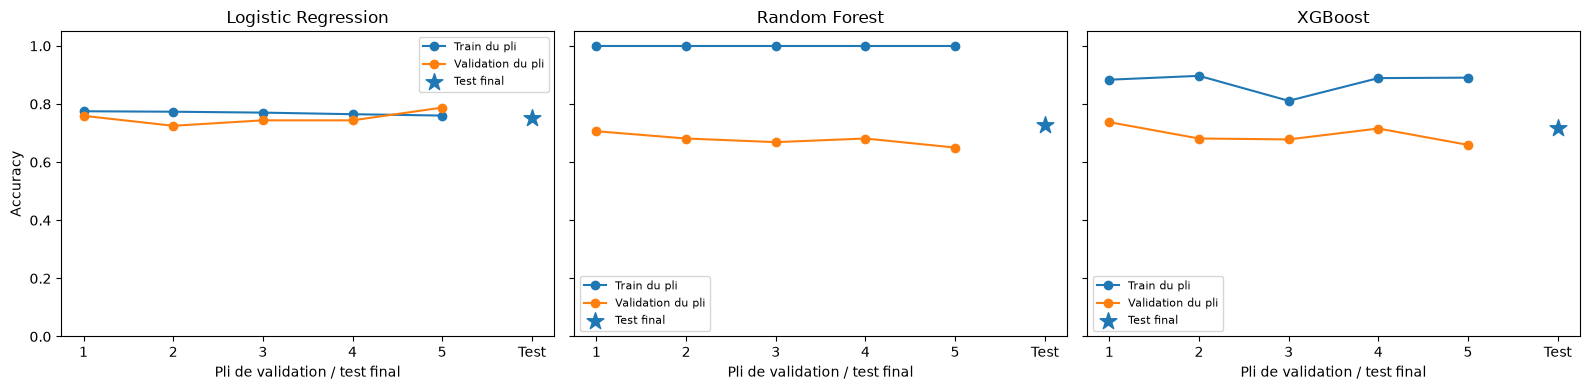

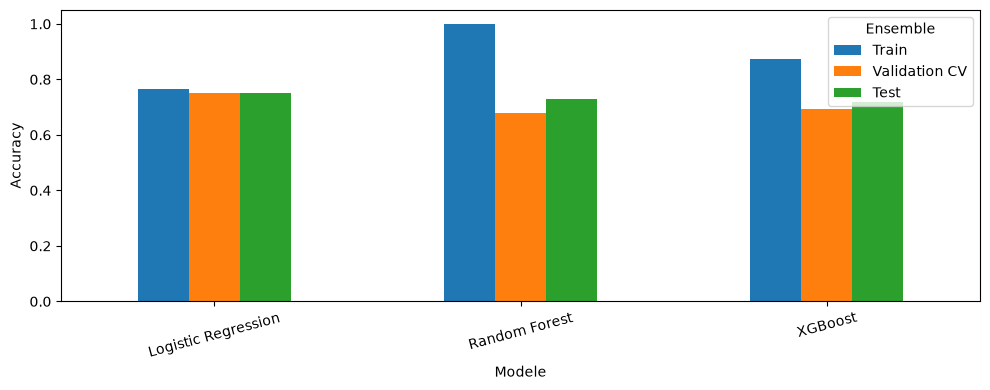

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, name in zip(axes, models):
    scores = fold_scores[fold_scores["Modele"] == name]
    ax.plot(scores["Fold"], scores["Accuracy train"], "o-", label="Train du pli")
    ax.plot(scores["Fold"], scores["Accuracy"], "o-", label="Validation du pli")
    ax.scatter([6], [results[name]["Test"]["metrics"]["Accuracy"]], marker="*", s=160, label="Test final")
    ax.set_xticks([1, 2, 3, 4, 5, 6], ["1", "2", "3", "4", "5", "Test"])
    ax.set_ylim(0, 1.05)
    ax.set_title(name)
    ax.set_xlabel("Pli de validation / test final")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Accuracy")
plt.tight_layout()
plt.savefig(folder / "accuracy_cv.png", dpi=160)
plt.show()

accuracy = metrics.pivot(index="Modele", columns="Ensemble", values="Accuracy")
accuracy = accuracy[["Train", "Validation CV", "Test"]]
accuracy.plot(kind="bar", figsize=(10, 4), ylim=(0, 1.05))
plt.ylabel("Accuracy")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(folder / "accuracy_train_validation_test.png", dpi=160)
plt.show()


## Limites a rappeler

Le test a deja ete regarde dans l'historique du projet : ne pas poursuivre les reglages selon ses scores.
Les essais de regularisation, de nouveaux modeles et de features sont des explorations anterieures,
avec des resultats archives. Ils n'ont pas etabli une nouvelle evaluation independante.
Le modele reste un prototype pedagogique des classes du dataset, sans utilisation clinique.
